# Coffee Customer Intelligence & 14-Day Repeat-Purchase Prediction

**Purpose:** Use real anonymized coffee transactions to study purchasing behavior and compare predictive models. This project predicts a **recorded card return within 14 days**, not permanent customer churn.

**Dataset:** [ihelon Coffee Sales on Kaggle](https://www.kaggle.com/datasets/ihelon/coffee-sales). Dates and quantities may change if Kaggle updates the source. **Run cells in order** in Google Colab.

**Methodological notes:** Card IDs are not verified unique people. The visit grouping window is an assumption. Weekly modeling snapshots share cards. Some historical test results were examined during exploratory work and should not be treated as a pristine holdout.


In [1]:

# Install Kaggle's dataset downloader
%pip -q install kagglehub

import kagglehub
import pandas as pd
from pathlib import Path

# Download dataset to the Colab environment
path = kagglehub.dataset_download("ihelon/coffee-sales")

# Find available CSV files
csv_files = list(Path(path).rglob("*.csv"))

print("Available CSV files:")
for file in csv_files:
    print(file.name)


Using Colab cache for faster access to the 'coffee-sales' dataset.
Available CSV files:
index_2.csv
index_1.csv


In [3]:

# List the available files and their sizes
for file in csv_files:
    temp = pd.read_csv(file)

    print("\nFilename:", file.name)
    print("Rows:", len(temp))
    print("Columns:", temp.columns.tolist())

# Inspect the combined dataframe
print("\nFirst 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

# Check for exact duplicates
print("\nDuplicate rows:", df.duplicated().sum())



Filename: index_2.csv
Rows: 262
Columns: ['date', 'datetime', 'cash_type', 'money', 'coffee_name']

Filename: index_1.csv
Rows: 3636
Columns: ['date', 'datetime', 'cash_type', 'card', 'money', 'coffee_name']

First 5 records:


,date,datetime,cash_type,money,coffee_name,card
0,2025-02-08,2025-02-08 14:26:04,cash,15.0,Tea,NaN
1,2025-02-08,2025-02-08 14:28:26,cash,15.0,Tea,NaN
2,2025-02-08,2025-02-08 14:33:04,card,20.0,Espresso,NaN
3,2025-02-08,2025-02-08 15:51:04,card,30.0,Chocolate with coffee,NaN
4,2025-02-08,2025-02-08 16:35:01,cash,27.0,Chocolate with milk,NaN



Last 5 records:


,date,datetime,cash_type,money,coffee_name,card
3893,2025-03-23,NaT,card,35.76,Cappuccino,ANON-0000-0000-1158
3894,2025-03-23,NaT,card,35.76,Cocoa,ANON-0000-0000-1315
3895,2025-03-23,NaT,card,35.76,Cocoa,ANON-0000-0000-1315
3896,2025-03-23,NaT,card,25.96,Americano,ANON-0000-0000-1316
3897,2025-03-23,NaT,card,35.76,Latte,ANON-0000-0000-1275



Duplicate rows: 439


## 1 · Validate source data and timestamps

The source contains CSV files with different schemas. Parsing mixed datetime formats avoids incorrectly truncating the observation period. Preserve source files and inspect repeated records rather than assuming they are errors.


In [4]:

import pandas as pd

# Reload the original CSV files
frames = []

for file in csv_files:
    temp = pd.read_csv(file, dtype=str)

    # Record the source filename
    temp["source_file"] = file.name

    frames.append(temp)

df_raw = pd.concat(frames, ignore_index=True)

# Convert money to numeric
df_raw["money"] = pd.to_numeric(
    df_raw["money"],
    errors="coerce"
)

# Parse different datetime formats
df_raw["datetime_parsed"] = pd.to_datetime(
    df_raw["datetime"],
    format="mixed",
    errors="coerce"
)

print("Total rows:", len(df_raw))

print("Missing timestamps:",
      df_raw["datetime_parsed"].isna().sum())

print("Date range:",
      df_raw["datetime_parsed"].min(),
      "to",
      df_raw["datetime_parsed"].max())

print("Exact raw duplicates:",
      df_raw.duplicated().sum())


Total rows: 3898
Missing timestamps: 0
Date range: 2024-03-01 10:15:50.520000 to 2025-03-23 21:23:11
Exact raw duplicates: 2


In [5]:

summary = df_raw.groupby(
    "source_file"
).agg(
    Transactions=("money", "size"),
    MissingTimestamps=(
        "datetime_parsed",
        lambda x: x.isna().sum()
    ),
    MissingCards=(
        "card",
        lambda x: x.isna().sum()
    ),
    UniqueCards=("card", "nunique"),
    EarliestDate=("datetime_parsed", "min"),
    LatestDate=("datetime_parsed", "max")
)

display(summary)


,Transactions,MissingTimestamps,MissingCards,UniqueCards,EarliestDate,LatestDate
source_file,,,,,,
index_1.csv,3636,0,89,1316,2024-03-01 10:15:50.520,2025-03-23 18:11:38.635
index_2.csv,262,0,262,0,2025-02-08 14:26:04.000,2025-03-23 21:23:11.000


In [6]:

# Columns originally representing transactions
transaction_columns = [
    "date",
    "datetime",
    "cash_type",
    "card",
    "money",
    "coffee_name"
]

# Exact duplicates based on original fields
duplicate_mask = df_raw.duplicated(
    subset=transaction_columns,
    keep=False
)

print(
    "Rows involved in duplicate groups:",
    duplicate_mask.sum()
)

print(
    "Repeated rows beyond first occurrence:",
    df_raw.duplicated(
        subset=transaction_columns
    ).sum()
)

# Inspect examples
display(
    df_raw.loc[
        duplicate_mask,
        transaction_columns + ["source_file"]
    ].head(15)
)


Rows involved in duplicate groups: 4
Repeated rows beyond first occurrence: 2


,date,datetime,cash_type,card,money,coffee_name,source_file
110,2025-02-26,2025-02-26 09:41:12,cash,NaN,25.0,Americano with milk,index_2.csv
111,2025-02-26,2025-02-26 09:41:12,cash,NaN,25.0,Americano with milk,index_2.csv
255,2025-03-23,2025-03-23 10:25:48,cash,NaN,25.0,Americano with milk,index_2.csv
256,2025-03-23,2025-03-23 10:25:48,cash,NaN,25.0,Americano with milk,index_2.csv


## 2 · Prepare card-linked data

Keep transactions with valid timestamp and positive amount. Retain original data separately; cash or cardless transactions cannot be used for card-level repeat-visit modeling.


In [7]:

# Create a working copy
df_clean = df_raw.copy()

# Use the correctly parsed timestamps
df_clean["datetime"] = df_clean["datetime_parsed"]

# Keep valid transactions
df_clean = df_clean[
    df_clean["datetime"].notna() &
    df_clean["money"].notna() &
    (df_clean["money"] > 0)
].copy()

# Keep transactions with card identifiers
df_customers = df_clean[
    df_clean["card"].notna()
].copy()

# Sort chronologically
df_customers = df_customers.sort_values(
    ["card", "datetime"]
)

print("Total valid transactions:", len(df_clean))
print("Identifiable transactions:", len(df_customers))
print("Unique card identifiers:",
      df_customers["card"].nunique())


Total valid transactions: 3898
Identifiable transactions: 3547
Unique card identifiers: 1316


## 3 · Customer behavior: recency, frequency and spending

These are descriptive, full-history measures. **Do not use full-history RFM fields as features for historical prediction.** Later training snapshots are rebuilt using only pre-cutoff data.


In [8]:

# Define analysis date
analysis_date = (
    df_customers["datetime"].max()
    + pd.Timedelta(days=1)
)

# Calculate customer metrics
customer_rfm = df_customers.groupby("card").agg(
    LastPurchase=("datetime", "max"),
    FirstPurchase=("datetime", "min"),
    Frequency=("datetime", "count"),
    TotalSpent=("money", "sum"),
    AvgPurchaseValue=("money", "mean")
)

# Calculate recency
customer_rfm["Recency"] = (
    analysis_date - customer_rfm["LastPurchase"]
).dt.total_seconds() / 86400

# Calculate customer history length
customer_rfm["CustomerAgeDays"] = (
    analysis_date - customer_rfm["FirstPurchase"]
).dt.total_seconds() / 86400

# Preview
display(customer_rfm.head())


,LastPurchase,FirstPurchase,Frequency,TotalSpent,AvgPurchaseValue,Recency,CustomerAgeDays
card,,,,,,,
ANON-0000-0000-0001,2024-06-06 10:36:09.667,2024-03-01 10:15:50.520,17,646.14,38.008235,291.316307,388.330418
ANON-0000-0000-0002,2024-03-01 12:20:18.089,2024-03-01 12:19:22.539,2,77.40,38.700000,388.243988,388.244631
ANON-0000-0000-0003,2024-10-18 09:34:08.021,2024-03-01 13:46:33.006,31,867.48,27.983226,157.359382,388.184093
ANON-0000-0000-0004,2024-10-04 09:30:22.038,2024-03-01 13:48:14.626,12,371.30,30.941667,171.361998,388.182917
ANON-0000-0000-0005,2024-03-01 15:39:47.726,2024-03-01 15:39:47.726,1,33.80,33.800000,388.105450,388.105450


In [9]:

print("Total identifiable customers:",
      len(customer_rfm))

print("\nAverage purchases per card:")
print(customer_rfm["Frequency"].mean())

print("\nMedian purchases per card:")
print(customer_rfm["Frequency"].median())

print("\nAverage customer spending:")
print(customer_rfm["TotalSpent"].mean())

print("\nTop 10 cards by purchase frequency:")
display(
    customer_rfm.sort_values(
        "Frequency", ascending=False
    ).head(10)
)


Total identifiable customers: 1316

Average purchases per card:
2.695288753799392

Median purchases per card:
1.0

Average customer spending:
85.29299392097265

Top 10 cards by purchase frequency:


,LastPurchase,FirstPurchase,Frequency,TotalSpent,AvgPurchaseValue,Recency,CustomerAgeDays
card,,,,,,,
ANON-0000-0000-0012,2025-01-20 08:29:47.959,2024-03-02 11:59:45.484,129,3785.92,29.348217,63.404059,387.258254
ANON-0000-0000-0141,2025-02-01 13:15:29.243,2024-04-29 11:26:31.871,108,2749.78,25.460926,51.205664,329.281328
ANON-0000-0000-1163,2025-03-21 15:29:32.330,2025-02-03 17:11:07.189,77,2278.22,29.587273,3.112573,49.042031
ANON-0000-0000-0276,2025-01-30 10:12:33.868,2024-06-09 12:11:23.640,69,2119.54,30.717971,53.332694,288.250174
ANON-0000-0000-0009,2024-08-10 16:06:12.085,2024-03-01 19:29:17.391,67,2343.98,34.984776,226.087113,387.946079
ANON-0000-0000-0507,2025-03-21 18:52:12.666,2024-08-14 21:41:33.021,51,1797.30,35.241176,2.971828,221.854232
ANON-0000-0000-0040,2024-12-19 19:10:40.561,2024-03-09 12:13:03.521,50,1519.48,30.389600,94.959005,380.249018
ANON-0000-0000-0097,2024-12-25 20:02:40.331,2024-04-05 12:14:27.975,47,1477.86,31.443830,88.922897,353.248040
ANON-0000-0000-1110,2025-03-21 15:28:19.564,2025-01-17 14:20:53.972,33,886.08,26.850909,3.113415,66.160239


### Descriptive customer segments

The 30-day recency and 5-purchase rules are exploratory business thresholds, **not** true churn labels.


In [10]:

import numpy as np

conditions = [
    (customer_rfm["Frequency"] >= 5) &
    (customer_rfm["Recency"] <= 30),

    (customer_rfm["Frequency"] >= 5) &
    (customer_rfm["Recency"] > 30),

    (customer_rfm["Frequency"] < 5) &
    (customer_rfm["Recency"] <= 30),

    (customer_rfm["Frequency"] < 5) &
    (customer_rfm["Recency"] > 30)
]

labels = [
    "Active Regulars",
    "At-Risk Regulars",
    "Recent Occasional",
    "Inactive Occasional"
]

customer_rfm["Segment"] = np.select(
    conditions,
    labels,
    default="Unclassified"
)

print(customer_rfm["Segment"].value_counts())


Segment
Inactive Occasional    1101
Recent Occasional        94
At-Risk Regulars         86
Active Regulars          35
Name: count, dtype: int64


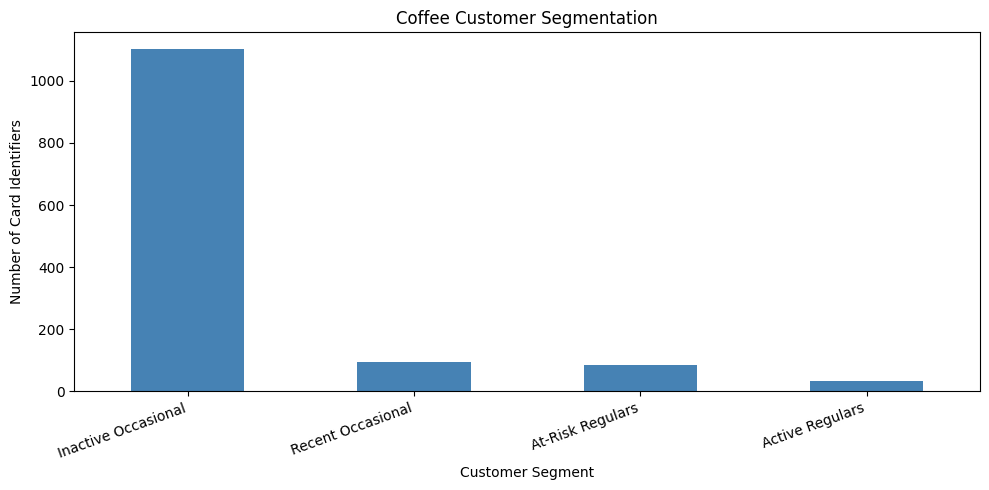

In [11]:

import matplotlib.pyplot as plt

segment_counts = (
    customer_rfm["Segment"].value_counts()
)

plt.figure(figsize=(10, 5))

segment_counts.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Coffee Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Card Identifiers")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


In [12]:

segment_summary = (
    customer_rfm.groupby("Segment")
    .agg(
        Customers=("Frequency", "size"),
        TotalRevenue=("TotalSpent", "sum"),
        AvgPurchases=("Frequency", "mean"),
        AvgSpending=("TotalSpent", "mean"),
        AvgRecency=("Recency", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

segment_summary["RevenueSharePct"] = (
    segment_summary["TotalRevenue"] /
    segment_summary["TotalRevenue"].sum()
    * 100
)

display(segment_summary.round(2))


,Customers,TotalRevenue,AvgPurchases,AvgSpending,AvgRecency,RevenueSharePct
Segment,,,,,,
Inactive Occasional,1101,52050.66,1.48,47.28,192.32,46.37
At-Risk Regulars,86,37653.24,14.05,437.83,153.24,33.55
Active Regulars,35,17068.14,15.49,487.66,8.88,15.21
Recent Occasional,94,5473.54,1.83,58.23,12.95,4.88


## 4 · Investigate inter-transaction gaps

Multiple same-visit purchases may appear as distinct transaction records. Inter-transaction gaps help motivate a visit grouping rule.


In [13]:

# Sort purchases chronologically
purchase_history = df_customers.sort_values(
    ["card", "datetime"]
).copy()

# Find the previous purchase for each card
purchase_history["PreviousPurchase"] = (
    purchase_history.groupby("card")["datetime"].shift(1)
)

# Calculate days since previous purchase
purchase_history["DaysBetweenPurchases"] = (
    purchase_history["datetime"] -
    purchase_history["PreviousPurchase"]
).dt.total_seconds() / 86400

# Show purchase intervals
display(
    purchase_history[
        ["card", "datetime", "PreviousPurchase",
         "DaysBetweenPurchases"]
    ].dropna().head(10)
)


,card,datetime,PreviousPurchase,DaysBetweenPurchases
290,ANON-0000-0000-0001,2024-03-04 10:03:51.994,2024-03-01 10:15:50.520,2.991684
294,ANON-0000-0000-0001,2024-03-05 09:59:52.651,2024-03-04 10:03:51.994,0.997230
475,ANON-0000-0000-0001,2024-04-02 10:01:14.022,2024-03-05 09:59:52.651,28.000942
587,ANON-0000-0000-0001,2024-04-19 10:10:36.254,2024-04-02 10:01:14.022,17.006507
608,ANON-0000-0000-0001,2024-04-21 11:16:45.707,2024-04-19 10:10:36.254,2.045943
621,ANON-0000-0000-0001,2024-04-24 10:19:38.346,2024-04-21 11:16:45.707,2.960331
633,ANON-0000-0000-0001,2024-04-26 10:12:50.618,2024-04-24 10:19:38.346,1.995281
643,ANON-0000-0000-0001,2024-04-28 10:32:52.479,2024-04-26 10:12:50.618,2.013910
694,ANON-0000-0000-0001,2024-05-08 10:07:28.863,2024-04-28 10:32:52.479,9.982366
716,ANON-0000-0000-0001,2024-05-12 10:20:42.512,2024-05-08 10:07:28.863,4.009186


In [14]:

gaps = purchase_history[
    "DaysBetweenPurchases"
].dropna()

print("Average gap:", round(gaps.mean(), 2), "days")
print("Median gap:", round(gaps.median(), 2), "days")

print("\nPurchase interval percentiles:")
print(
    gaps.quantile([0.25, 0.50, 0.75, 0.90, 0.95])
    .round(2)
)

print("\nTotal observed repeat-purchase gaps:", len(gaps))


Average gap: 9.18 days
Median gap: 1.4 days

Purchase interval percentiles:
0.25     0.00
0.50     1.40
0.75     6.17
0.90    21.16
0.95    46.27
Name: DaysBetweenPurchases, dtype: float64

Total observed repeat-purchase gaps: 2231


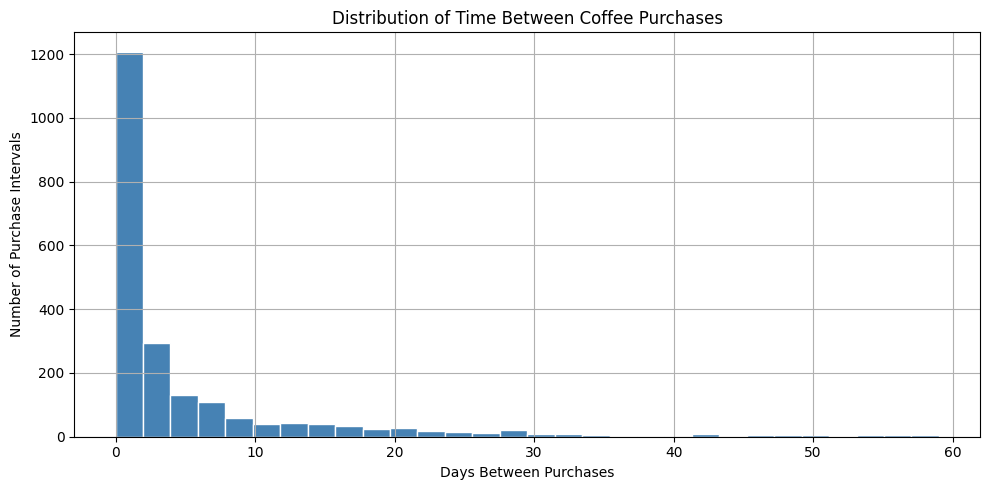

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Focus on gaps up to 60 days for readability
gaps[gaps <= 60].hist(
    bins=30,
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Time Between Coffee Purchases")
plt.xlabel("Days Between Purchases")
plt.ylabel("Number of Purchase Intervals")
plt.tight_layout()
plt.show()


## 5 · Estimate customer visits

Consecutive transactions for a single card less than or equal to 30 minutes apart are grouped as one estimated visit. This is a transparent heuristic, not a verified visit identifier.


In [4]:

# Sort transactions by card and time
visits = df_customers.sort_values(
    ["card", "datetime"]
).copy()

# Time since previous purchase
visits["TimeSincePrevious"] = (
    visits.groupby("card")["datetime"].diff()
)

# Define a new visit after 30 minutes
visits["NewVisit"] = (
    visits["TimeSincePrevious"].isna() |
    (visits["TimeSincePrevious"] >
     pd.Timedelta(minutes=30))
).astype(int)

# Number visits for each card
visits["VisitNumber"] = (
    visits.groupby("card")["NewVisit"].cumsum()
)

# Aggregate transactions into visits
customer_visits = (
    visits.groupby(["card", "VisitNumber"])
    .agg(
        VisitDate=("datetime", "min"),
        VisitSpending=("money", "sum"),
        ItemsPurchased=("coffee_name", "count")
    )
    .reset_index()
)

print("Estimated visits:", len(customer_visits))
display(customer_visits.head())


Estimated visits: 2886


,card,VisitNumber,VisitDate,VisitSpending,ItemsPurchased
0,ANON-0000-0000-0001,1,2024-03-01 10:15:50.520,38.7,1
1,ANON-0000-0000-0001,2,2024-03-04 10:03:51.994,38.7,1
2,ANON-0000-0000-0001,3,2024-03-05 09:59:52.651,38.7,1
3,ANON-0000-0000-0001,4,2024-04-02 10:01:14.022,38.7,1
4,ANON-0000-0000-0001,5,2024-04-19 10:10:36.254,38.7,1


In [5]:

customer_visits["PreviousVisit"] = (
    customer_visits.groupby("card")["VisitDate"]
    .shift(1)
)

customer_visits["DaysBetweenVisits"] = (
    customer_visits["VisitDate"] -
    customer_visits["PreviousVisit"]
).dt.total_seconds() / 86400

gaps = customer_visits["DaysBetweenVisits"].dropna()

print("Average gap:", round(gaps.mean(), 2))
print("Median gap:", round(gaps.median(), 2))

print("\nVisit gap percentiles:")
print(gaps.quantile([0.25, 0.50, 0.75, 0.90, 0.95]).round(2))

visit_counts = customer_visits.groupby("card").size()

print("\nCards with 1 visit:", (visit_counts == 1).sum())
print("Cards with 2+ visits:", (visit_counts >= 2).sum())
print("Cards with 5+ visits:", (visit_counts >= 5).sum())
print("Cards with 10+ visits:", (visit_counts >= 10).sum())


Average gap: 13.05
Median gap: 3.03

Visit gap percentiles:
0.25     1.08
0.50     3.03
0.75    11.08
0.90    29.05
0.95    60.80
Name: DaysBetweenVisits, dtype: float64

Cards with 1 visit: 977
Cards with 2+ visits: 339
Cards with 5+ visits: 89
Cards with 10+ visits: 36


## 6 · Build time-aware prediction snapshots

Create features at weekly cutoff dates and label the presence or absence of a recorded visit in the next 14 days. Outcome windows must have adequate observation time.


In [6]:

import pandas as pd
import numpy as np

# Keep necessary columns
visit_data = customer_visits[
    ["card", "VisitDate", "VisitSpending",
     "ItemsPurchased"]
].copy()

visit_data = visit_data.sort_values(
    ["card", "VisitDate"]
)

# Create weekly prediction dates
start_date = (
    visit_data["VisitDate"].min()
    + pd.Timedelta(days=60)
)

end_date = (
    visit_data["VisitDate"].max()
    - pd.Timedelta(days=14)
)

cutoff_dates = pd.date_range(
    start=start_date,
    end=end_date,
    freq="7D"
)

print("Number of cutoff dates:", len(cutoff_dates))
print("First cutoff:", cutoff_dates.min())
print("Last cutoff:", cutoff_dates.max())


Number of cutoff dates: 45
First cutoff: 2024-04-30 10:15:50.520000
Last cutoff: 2025-03-04 10:15:50.520000


In [7]:

training_rows = []

for cutoff in cutoff_dates:

    # Historical purchases only
    past = visit_data[
        visit_data["VisitDate"] < cutoff
    ]

    # Future purchases for labeling
    future = visit_data[
        (visit_data["VisitDate"] >= cutoff) &
        (visit_data["VisitDate"] <
         cutoff + pd.Timedelta(days=14))
    ]

    # Calculate historical customer features
    features = past.groupby("card").agg(
        LastVisit=("VisitDate", "max"),
        FirstVisit=("VisitDate", "min"),
        TotalVisits=("VisitDate", "count"),
        TotalSpent=("VisitSpending", "sum"),
        AvgVisitSpending=("VisitSpending", "mean")
    )

    # Recency at prediction date
    features["RecencyDays"] = (
        cutoff - features["LastVisit"]
    ).dt.total_seconds() / 86400

    # Historical relationship length
    features["CustomerAgeDays"] = (
        cutoff - features["FirstVisit"]
    ).dt.total_seconds() / 86400

    # Target: return during next 14 days
    returning_cards = set(future["card"])

    features["Returned14Days"] = (
        features.index.isin(returning_cards)
        .astype(int)
    )

    features["CutoffDate"] = cutoff

    training_rows.append(
        features.reset_index()
    )

# Combine all historical snapshots
ml_data = pd.concat(
    training_rows, ignore_index=True
)

print("Machine learning dataset shape:",
      ml_data.shape)

display(ml_data.head())


Machine learning dataset shape: (31486, 10)


,card,LastVisit,FirstVisit,TotalVisits,TotalSpent,AvgVisitSpending,RecencyDays,CustomerAgeDays,Returned14Days,CutoffDate
0,ANON-0000-0000-0001,2024-04-28 10:32:52.479,2024-03-01 10:15:50.520,9,344.38,38.264444,1.988172,60.000000,1,2024-04-30 10:15:50.520
1,ANON-0000-0000-0002,2024-03-01 12:19:22.539,2024-03-01 12:19:22.539,1,77.40,77.400000,59.914213,59.914213,0,2024-04-30 10:15:50.520
2,ANON-0000-0000-0003,2024-04-29 13:27:56.949,2024-03-01 13:46:33.006,10,489.34,48.934000,0.866592,59.853675,0,2024-04-30 10:15:50.520
3,ANON-0000-0000-0004,2024-04-15 17:02:49.748,2024-03-01 13:48:14.626,6,289.50,48.250000,14.717370,59.852499,0,2024-04-30 10:15:50.520
4,ANON-0000-0000-0005,2024-03-01 15:39:47.726,2024-03-01 15:39:47.726,1,33.80,33.800000,59.775032,59.775032,0,2024-04-30 10:15:50.520


In [8]:

print("Target distribution:")
print(ml_data["Returned14Days"].value_counts())

print("\nTarget percentages:")
print(
    ml_data["Returned14Days"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nUnique cards represented:",
      ml_data["card"].nunique())

print("\nTotal prediction snapshots:",
      len(ml_data))


Target distribution:
Returned14Days
0    30368
1     1118
Name: count, dtype: int64

Target percentages:
Returned14Days
0    96.45
1     3.55
Name: proportion, dtype: float64

Unique cards represented: 1260

Total prediction snapshots: 31486


## 7 · Exploratory baseline and candidate models

The first chronological split and threshold comparison were used for exploration. These test-period outcomes were already reviewed, so do **not** claim they form an untouched final holdout.


In [9]:

# Get all prediction dates
dates = sorted(ml_data["CutoffDate"].unique())

# Reserve the final 8 cutoff dates for testing
test_start = dates[-8]

# Stop training before the test period
# Two weekly cutoff dates are excluded as a gap
train_end = dates[-11]

train_data = ml_data[
    ml_data["CutoffDate"] <= train_end
].copy()

test_data = ml_data[
    ml_data["CutoffDate"] >= test_start
].copy()

print("Training snapshots:", len(train_data))
print("Testing snapshots:", len(test_data))

print("\nTraining positive rate:")
print(train_data["Returned14Days"].mean())

print("\nTesting positive rate:")
print(test_data["Returned14Days"].mean())

print("\nLast training cutoff:", train_end)
print("First testing cutoff:", test_start)


Training snapshots: 19901
Testing snapshots: 9445

Training positive rate:
0.041706446912215464

Testing positive rate:
0.02541026998411858

Last training cutoff: 2024-12-24 10:15:50.520000
First testing cutoff: 2025-01-14 10:15:50.520000


In [10]:

features = [
    "TotalVisits",
    "TotalSpent",
    "AvgVisitSpending",
    "RecencyDays",
    "CustomerAgeDays"
]

X_train = train_data[features]
y_train = train_data["Returned14Days"]

X_test = test_data[features]
y_test = test_data["Returned14Days"]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)


Training features: (19901, 5)
Testing features: (9445, 5)


In [11]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

# Baseline model
baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)

# Logistic Regression model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

model.fit(X_train, y_train)

print("Both models trained successfully!")


Both models trained successfully!


In [12]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

def evaluate_model(name, model, X, y):
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "F1": f1_score(
            y, predictions, zero_division=0
        ),
        "AveragePrecision": average_precision_score(
            y, probabilities
        ),
        "ROC_AUC": (
            roc_auc_score(y, probabilities)
            if y.nunique() == 2 else float("nan")
        )
    }

results = pd.DataFrame([
    evaluate_model(
        "Baseline", baseline, X_test, y_test
    ),
    evaluate_model(
        "Logistic Regression", model, X_test, y_test
    )
])

display(results.round(4))


,Model,Accuracy,Precision,Recall,F1,AveragePrecision,ROC_AUC
0,Baseline,0.9746,0.0000,0.0000,0.0000,0.0254,0.500
1,Logistic Regression,0.8861,0.1709,0.9042,0.2874,0.2389,0.922


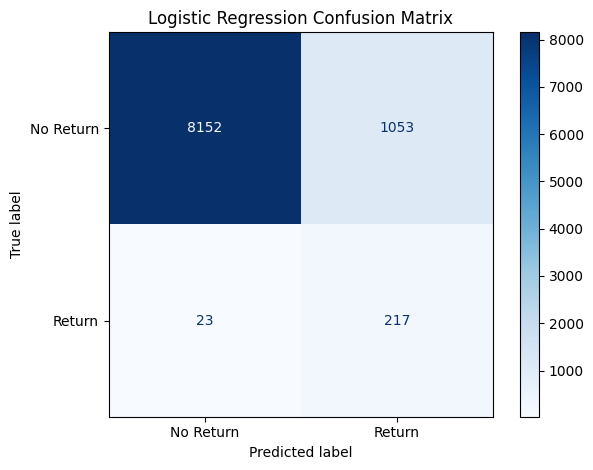

In [13]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    display_labels=["No Return", "Return"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()


In [14]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Predicted probabilities from Logistic Regression
probabilities = model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]:
    predictions = (
        probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "PredictedReturns": predictions.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))


,Threshold,Precision,Recall,F1,PredictedReturns
0,0.3,0.089,0.921,0.162,2488
1,0.5,0.171,0.904,0.287,1270
2,0.6,0.250,0.796,0.381,763
3,0.7,0.273,0.462,0.344,406
4,0.8,0.269,0.283,0.276,253
5,0.9,0.221,0.142,0.173,154


In [15]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

rf_results = evaluate_model(
    "Random Forest",
    rf_model,
    X_test,
    y_test
)

all_results = pd.concat(
    [results, pd.DataFrame([rf_results])],
    ignore_index=True
)

display(all_results.round(4))


Random Forest trained successfully!


,Model,Accuracy,Precision,Recall,F1,AveragePrecision,ROC_AUC
0,Baseline,0.9746,0.0000,0.0000,0.0000,0.0254,0.5000
1,Logistic Regression,0.8861,0.1709,0.9042,0.2874,0.2389,0.9220
2,Random Forest,0.9456,0.2694,0.6667,0.3837,0.4374,0.9227


RecencyDays         0.403483
TotalSpent          0.206818
TotalVisits         0.179721
CustomerAgeDays     0.147913
AvgVisitSpending    0.062066
dtype: float64


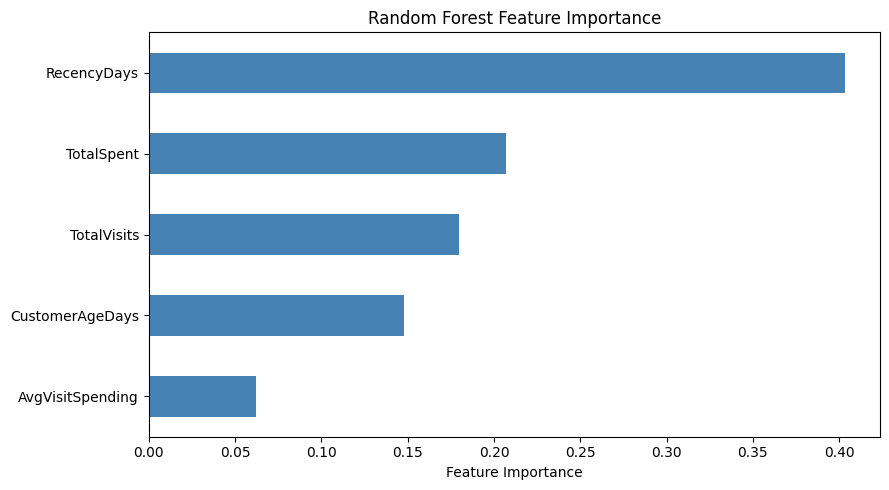

In [16]:

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(feature_importance)

feature_importance.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue",
    title="Random Forest Feature Importance"
)

plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


## 8 · Chronological training, validation and retrospective testing

Use an earlier training period and a later validation period for model selection. Two unused weekly cutoffs separate periods. Because prior exploration examined test results, the final period is a retrospective check rather than a pristine independent holdout.


In [17]:

dates = sorted(ml_data["CutoffDate"].unique())

train_dates = dates[:24]
val_dates = dates[26:35]
test_dates = dates[37:]

train = ml_data[
    ml_data["CutoffDate"].isin(train_dates)
].copy()

val = ml_data[
    ml_data["CutoffDate"].isin(val_dates)
].copy()

test = ml_data[
    ml_data["CutoffDate"].isin(test_dates)
].copy()

print("Training:", len(train))
print("Validation:", len(val))
print("Testing:", len(test))

print("\nPositive return rates:")
for name, data in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(name, round(
        data["Returned14Days"].mean() * 100, 2
    ), "%")


Training: 9879
Validation: 8461
Testing: 9445

Positive return rates:
Train 5.34 %
Validation 2.58 %
Test 2.54 %


In [18]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

features = [
    "TotalVisits",
    "TotalSpent",
    "AvgVisitSpending",
    "RecencyDays",
    "CustomerAgeDays"
]

X_train = train[features]
y_train = train["Returned14Days"]

X_val = val[features]
y_val = val["Returned14Days"]

lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

lr.fit(X_train, y_train)
rf.fit(X_train, y_train)

print("Both models trained!")


Both models trained!


In [19]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

validation_results = []

for name, clf in [
    ("Logistic Regression", lr),
    ("Random Forest", rf)
]:
    probabilities = clf.predict_proba(X_val)[:, 1]

    validation_results.append({
        "Model": name,
        "AveragePrecision": average_precision_score(
            y_val, probabilities
        ),
        "ROC_AUC": roc_auc_score(
            y_val, probabilities
        )
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df.round(4))


,Model,AveragePrecision,ROC_AUC
0,Logistic Regression,0.3769,0.8826
1,Random Forest,0.4407,0.8646


In [20]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

X_test = test[features]
y_test = test["Returned14Days"]

# Get Random Forest probabilities
rf_probs = rf.predict_proba(X_test)[:, 1]

# Default threshold
rf_predictions = (rf_probs >= 0.5).astype(int)

print("Accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))

print("Precision:",
      round(precision_score(y_test, rf_predictions,
                            zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, rf_predictions,
                         zero_division=0), 4))

print("F1:",
      round(f1_score(y_test, rf_predictions,
                     zero_division=0), 4))

print("Average Precision:",
      round(average_precision_score(y_test, rf_probs), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, rf_probs), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, rf_predictions))


Accuracy: 0.9323
Precision: 0.2286
Recall: 0.7
F1: 0.3446
Average Precision: 0.4276
ROC-AUC: 0.9185

Confusion matrix:
[[8638  567]
 [  72  168]]


## 9 · Business interpretation and model limitations

The return rate is strongly associated with recency, but observational data cannot prove that offers will change behavior. Prefer controlled experiments to assess incrementality.


In [21]:

cutoff_summary = (
    ml_data.groupby("CutoffDate")
    .agg(
        TotalCards=("card", "nunique"),
        ReturningCards=("Returned14Days", "sum"),
        ReturnRate=("Returned14Days", "mean")
    )
    .reset_index()
)

cutoff_summary["ReturnRatePct"] = (
    cutoff_summary["ReturnRate"] * 100
)

display(cutoff_summary.tail(10))


,CutoffDate,TotalCards,ReturningCards,ReturnRate,ReturnRatePct
35,2024-12-31 10:15:50.520,1061,23,0.021678,2.167766
36,2025-01-07 10:15:50.520,1079,25,0.023170,2.316960
37,2025-01-14 10:15:50.520,1099,21,0.019108,1.910828
38,2025-01-21 10:15:50.520,1115,18,0.016143,1.614350
39,2025-01-28 10:15:50.520,1132,15,0.013251,1.325088
40,2025-02-04 10:15:50.520,1168,18,0.015411,1.541096
41,2025-02-11 10:15:50.520,1201,39,0.032473,3.247294
42,2025-02-18 10:15:50.520,1223,44,0.035977,3.597711
43,2025-02-25 10:15:50.520,1247,44,0.035285,3.528468
44,2025-03-04 10:15:50.520,1260,41,0.032540,3.253968


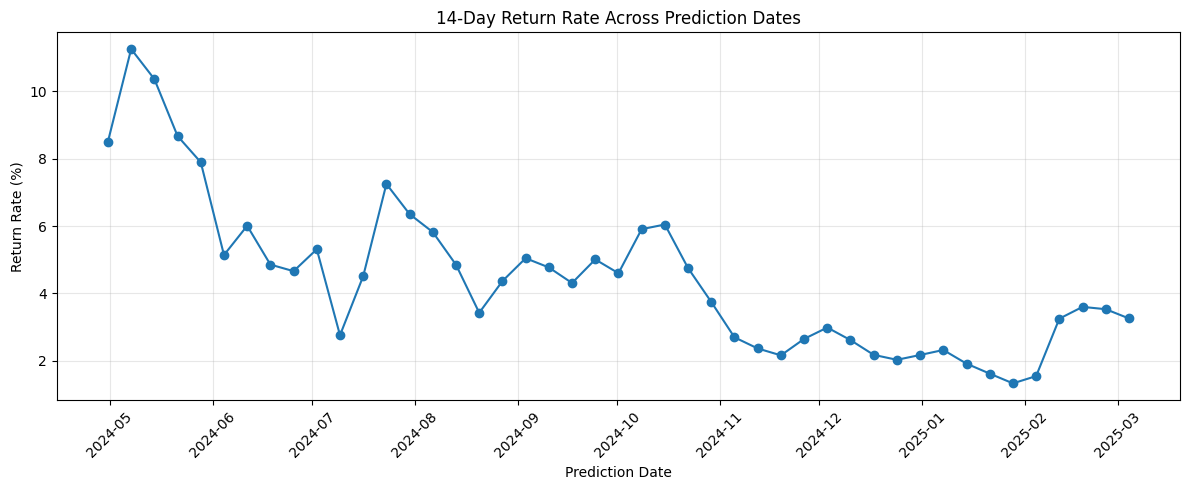

In [22]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    cutoff_summary["CutoffDate"],
    cutoff_summary["ReturnRatePct"],
    marker="o"
)

plt.title("14-Day Return Rate Across Prediction Dates")
plt.xlabel("Prediction Date")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [23]:

# Create activity groups on the test set
test_analysis = test.copy()

test_analysis["RecencyGroup"] = pd.cut(
    test_analysis["RecencyDays"],
    bins=[0, 7, 30, 90, float("inf")],
    labels=[
        "0–7 days",
        "8–30 days",
        "31–90 days",
        "90+ days"
    ],
    include_lowest=True
)

recency_analysis = (
    test_analysis.groupby(
        "RecencyGroup",
        observed=True
    )
    .agg(
        Snapshots=("Returned14Days", "size"),
        Returns=("Returned14Days", "sum"),
        ReturnRate=("Returned14Days", "mean")
    )
)

recency_analysis["ReturnRatePct"] = (
    recency_analysis["ReturnRate"] * 100
)

display(recency_analysis.round(2))


,Snapshots,Returns,ReturnRate,ReturnRatePct
RecencyGroup,,,,
0–7 days,354,163,0.46,46.05
8–30 days,670,53,0.08,7.91
31–90 days,1960,9,0.00,0.46
90+ days,6461,15,0.00,0.23


## Final takeaways

- **Selected candidate:** Random Forest on **validation Average Precision** (0.4407), compared with Logistic Regression (0.3769); Logistic Regression had the higher validation ROC-AUC.
- **Retrospective Random Forest test:** AP 0.4276; ROC-AUC 0.9185; precision 0.2286 and recall 0.7000 at a 0.5 threshold. This is not a pristine holdout because the test period was examined during the exploratory workflow.
- **Business observation:** Recently used cards were much more likely to appear again within 14 days than long-inactive cards. This does **not** demonstrate that loyalty rewards or discounts would cause incremental visits.
- **Potential next business action:** Run a randomized trial of targeted engagement and compare incremental customer visits and profit against a control group.
- **Cautions:** Cards ≠ customers; visits are estimated; repeat snapshots are correlated; this is repeat-purchase prediction, not permanent churn.
